# **Final Year Project - Year 4 Software Development**
## Iteration 2 - RMS Onset Detection - Refinement/Investigation

*By Mark Lambert - C00192497*

*14/11/2026*

---

I spent some time testing the current onset and chord detection, and faced some difficulties when trying to cleanly get a recording that detects every major chord

This notebook investigates this issue by once again digging deeper and plotting the onsets to understand what's going wrong

In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

clip, sr = librosa.load("../data/clips/sample/all_chords.wav", sr=None)
raw_onsets = librosa.onset.onset_detect(y=clip, sr=sr)
raw_onset_times = librosa.frames_to_time(raw_onsets, sr=sr)

rms = librosa.feature.rms(y=clip)[0]
onset_frames = librosa.onset.onset_detect(y=clip, sr=sr)
chroma = librosa.feature.chroma_cqt(y=clip, sr=sr)
onset_frames = np.append(onset_frames, chroma.shape[1])

valid_threshold = 0.2 * rms.max()
frame_offset = 2
buffer = 0.5
min_len = int(librosa.time_to_frames(buffer, sr=sr))

# lists of tuples w/ (start, end) frames
strum_group = []
transition_group = []

# list of valid strum onsets detected by rms
strums = []

In [2]:
# lists of tuples w/ (start, end) frames
strum_group = []
transition_group = []

# list of valid strum onsets detected by rms
strums_end = []
strums_start = []
strums = []
# find strum end onsets
for i in range(len(onset_frames)):
    frame = onset_frames[i]

    # only check for strum end onsets if there has already been a detected onset
    if i > 0:
        prev = onset_frames[i-1]
        cur = onset_frames[i]

        frame_since_last = cur - prev
        if librosa.frames_to_time(frame_since_last, sr=sr) > buffer:
            strums_end.append(cur)
            strums.append(cur)
            continue
    
    # find starts w/ rms
    if frame < len(rms):
        curr = rms[frame]
        prev = rms[frame-frame_offset]
    
    # check if above valid threshold (filter noise) and
    # curr is louder than preevious, showing rise in energy
    if curr > valid_threshold and curr > 1.4 * prev:
        strums_start.append(frame)
        strums.append(frame)
# sort the strum list so that they are in chronological order
strums = sorted(set(strums))
strums = librosa.frames_to_time(strums, sr=sr)
strums_end = sorted(set(strums_end))
strums_end = librosa.frames_to_time(strums_end, sr=sr)
strums_start = sorted(set(strums_start))
strums_start = librosa.frames_to_time(strums_start, sr=sr)

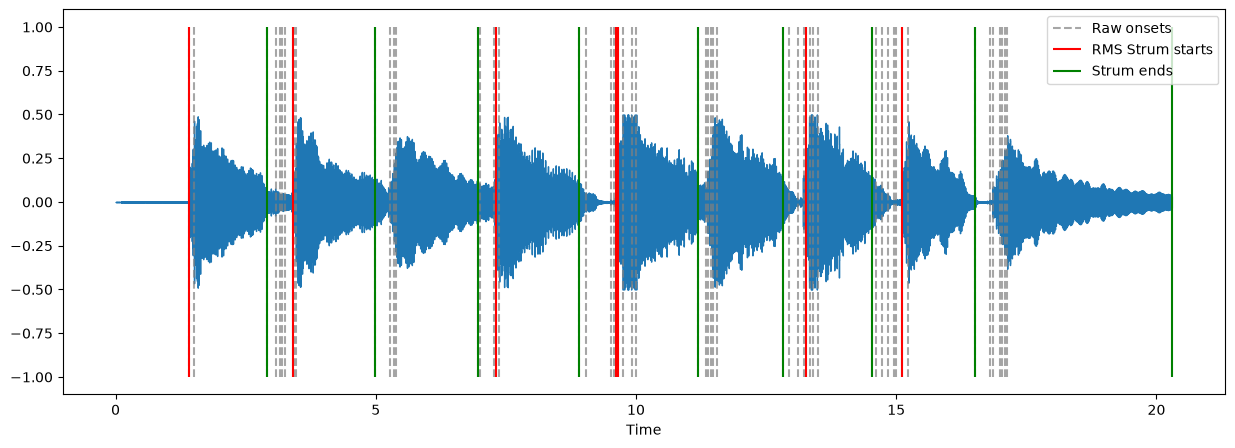

In [3]:
fig, ax = plt.subplots(figsize=(15, 5))
librosa.display.waveshow(clip, sr=sr, ax=ax)

ax.vlines(raw_onset_times, -1, 1, color="grey", linestyle="--", alpha=0.7, label="Raw onsets")
ax.vlines(strums_start, -1, 1, color="red", linestyle="-", label="RMS Strum starts")
ax.vlines(strums_end, -1, 1, color="green", linestyle="-", label="Strum ends")
ax.set_xlabel("Time")
ax.legend()
plt.show()

So, the red lines show that the rms based detection is not currently reliable, with the logic failing to detect three of the 9 played chords

From watching [this video](https://www.youtube.com/watch?v=TXPQrJq0ak0) who references the [MusicInformatioNRetrieval](https://musicinformationretrieval.com/intro.html) repository


I read through their onset detection notebooks and pulled the following code to listen to the onsets from their [onset segmentation tutorial](https://musicinformationretrieval.com/content/4_rhythm_tempo_beat/onset_segmentation.html)

In [4]:
import IPython.display as ipd

starts = strums[0::2]
ends = strums[1::2]
def concatenate_segments(x, segments, sr, pad_duration=0.500):
    """Concatenate (start, end) segments, given in seconds, into one signal."""
    silence = np.zeros(int(pad_duration * sr))
    return np.concatenate(
        [
            np.concatenate([x[int(s * sr):int(e * sr)], silence])
            for s, e in segments
        ]
    )

strum_segments = list(zip(starts, ends))
transition_segments = [
    (ends[i], starts[i + 1])
    for i in range(len(ends) - 1)
    if ends[i] < starts[i + 1]
]
print("Strum slices")
ipd.Audio(concatenate_segments(clip, strum_segments, sr), rate=sr)

Strum slices


In [5]:
print("Transition slices")
ipd.Audio(concatenate_segments(clip, transition_segments, sr), rate=sr)

Transition slices


What I know: there are four stages to a note onset, attack, decay, sustain and release. RMS calculates the energy level for each frame of the audio clip. RMS is returned with one value per frame

My problem: I calculate the RMS in my function and read it for one single frame entry `curr = rms[frame]`. This is an issue because onsets are marked at the **start** of an **attack**, so the RMS value may not have swelled to reach the threshold of being 1.5 times louder than the previous frames RMS. This is why my original function with RMS had missing strum starts, leading to misaligned strum/transition slices

[Antoni Jankowski](https://youtu.be/2YykLX5nCDQ?t=71) has a good video detailing onset detection

In [6]:
clip, sr = librosa.load("../data/clips/sample/all_chords.wav", sr=None)

raw_onsets = librosa.onset.onset_detect(y=clip, sr=sr)
raw_onset_times = librosa.frames_to_time(raw_onsets, sr=sr)
rms = librosa.feature.rms(y=clip)[0]
onset_frames = librosa.onset.onset_detect(y=clip, sr=sr)
total_frames = len(rms)

valid_threshold = 0.2 * rms.max()
transition_threshold = 0.08 * rms.max()

frame_offset = 2
buffer = 0.5

# lists of tuples w/ (start, end) frames
strum_group = []
transition_group = []

# list of valid strum onsets detected by rms
strums = []

for frame in onset_frames:
    if strums:
        time_since_last_strum = librosa.frames_to_time(frame - strums[-1], sr=sr)
        if time_since_last_strum < buffer:
            continue

    # look @ max RMS within the next 5 frames (current, plus next 5 = 6) to capture full strum swell
    window_end = frame+6
    peak_rms = np.max(rms[frame:window_end])

    # get the rms of the previous frame, if the current one is 1.5 times louder, it has attack
    # that can be classified as a strum
    prev = frame - frame_offset
    if prev < 0:
        prev = 0
    prev_rms = rms[prev]

    if peak_rms > valid_threshold and peak_rms > 1.5 * prev_rms:
        strums.append(frame)
        
starts = strums
strums = []
min_len = int(librosa.time_to_frames(buffer, sr=sr))
no_strums = len(starts)

for i, start in enumerate(starts):
    # runs until the next strum OR end of clip for last strum
    end = starts[i + 1] if i + 1 < no_strums else total_frames

    # first raw onset after the cooldown window and before the next strum
    pre = onset_frames[(onset_frames > start + min_len) & (onset_frames < end)]
    if pre.size:
        end = pre[0]

    strums.append(start)
    strums.append(end)
# sort the strum list so that they are in chronological order
strums = sorted(set(strums))

strums = librosa.frames_to_time(strums, sr=sr)

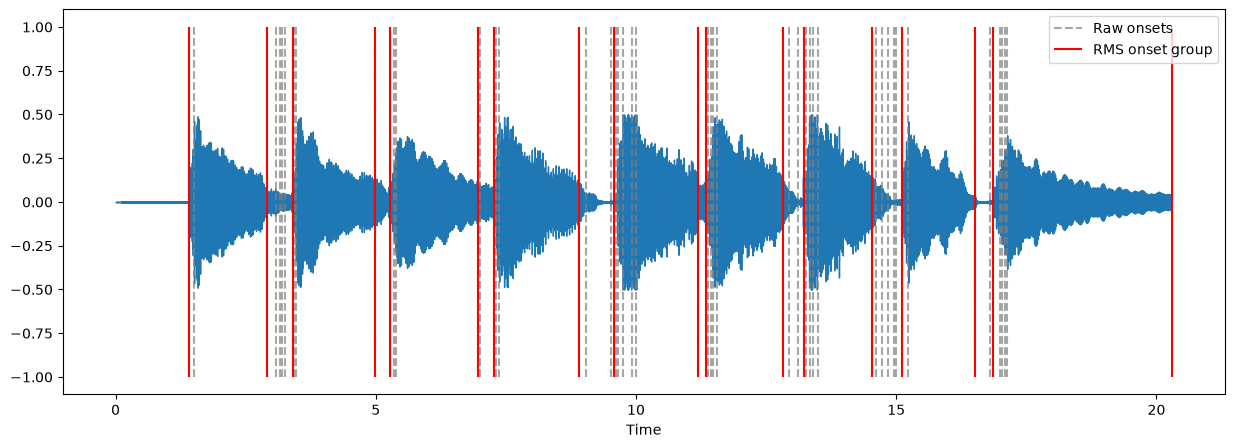

In [7]:
fig, ax = plt.subplots(figsize=(15, 5))
librosa.display.waveshow(clip, sr=sr, ax=ax)

ax.vlines(raw_onset_times, -1, 1, color="grey", linestyle="--", alpha=0.7, label="Raw onsets")
ax.vlines(strums, -1, 1, color="red", linestyle="-", label="RMS onset group")
ax.set_xlabel("Time")
ax.legend()
plt.show()

In [8]:
print("Strum slices")
ipd.Audio(concatenate_segments(clip, strum_segments, sr), rate=sr)

Strum slices


In [9]:
print("Transition slices")
ipd.Audio(concatenate_segments(clip, transition_segments, sr), rate=sr)

Transition slices


To refine the function further, by extracting each single piece of functionality into their own sub-functions

In [10]:
clip, sr = librosa.load("../data/clips/sample/all_chords.wav", sr=None)
raw_onsets = librosa.onset.onset_detect(y=clip, sr=sr)
raw_onset_times = librosa.frames_to_time(raw_onsets, sr=sr)

rms = librosa.feature.rms(y=clip)[0]
onset_frames = librosa.onset.onset_detect(y=clip, sr=sr)
onset_frames = np.append(onset_frames, chroma.shape[1])
chroma = librosa.feature.chroma_cqt(y=clip, sr=sr)

valid_threshold = 0.2 * rms.max()
frame_offset = 2
buffer = 0.5
min_len = int(librosa.time_to_frames(buffer, sr=sr))
total_frames = len(rms)

def get_strum_starts():
    starts = []
    for frame in onset_frames:
        if frame >= len(rms):
            continue
        if starts:
            time_since_last_strum = librosa.frames_to_time(frame - starts[-1], sr=sr)
            if time_since_last_strum < buffer:
                continue
    
        # look @ max RMS within the next 5 frames (current, plus next 5 = 6) to capture full strum swell
        window_end = frame+6
        peak_rms = np.max(rms[frame:window_end])
    
        # get the rms of the previous frame, if the current one is 1.5 times louder, it has attack
        # that can be classified as a strum
        prev = frame - frame_offset
        if prev < 0:
            prev = 0
        prev_rms = rms[prev]
    
        if peak_rms > valid_threshold and peak_rms > 1.5 * prev_rms:
            starts.append(frame)
            
    return starts
    
def get_strum_ends(starts):
    no_strums = len(starts)
    strums = []
    for i, start in enumerate(starts):
        # runs until the next strum OR end of clip for last strum
        end = starts[i + 1] if i + 1 < no_strums else total_frames
    
        # first raw onset after the cooldown window and before the next strum
        pre = onset_frames[(onset_frames > start + min_len) & (onset_frames < end)]
        if pre.size:
            end = pre[0]
    
        strums.append(start)
        strums.append(end)
    # sort the strum list so that they are in chronological order
    strums = sorted(set(strums))
    
    return strums

In [11]:
starts = get_strum_starts()
strums = get_strum_ends(starts)

Then, with all of the offsets marked, I can process them into their own strum and transition tuples containing (start, end) frames

In [12]:
def get_strums_and_transitions(strums):
    strum_group = []
    transition_group = []
    for i in range(len(strums) - 1):
        start = strums[i]
        end = strums[i+1]

        if start >= end:
            continue

        # rms always calculates the first strum, so 
        # i mod 2 = 0 means we are on even index (0, 2, 4) 
        # and all even indices are strum segments
        if i % 2 == 0:
            strum_group.append((start, end))
        # otherwise the mod result is 1, so any odd
        # index is a transition segment
        else:
            transition_group.append((start, end))
    return strum_group, transition_group

In [13]:
strum_group, transitions = get_strums_and_transitions(strums)

In [14]:
strums_times = librosa.frames_to_time(strum_group, sr=sr)
transitions_times = librosa.frames_to_time(transitions, sr=sr)

The final plots for both groups show each slice of strums and transitions are cleanly marked, resolving the issues faced with my initial approach of only querying a single frame of the rms, rather than covering a window and calculating the average rms

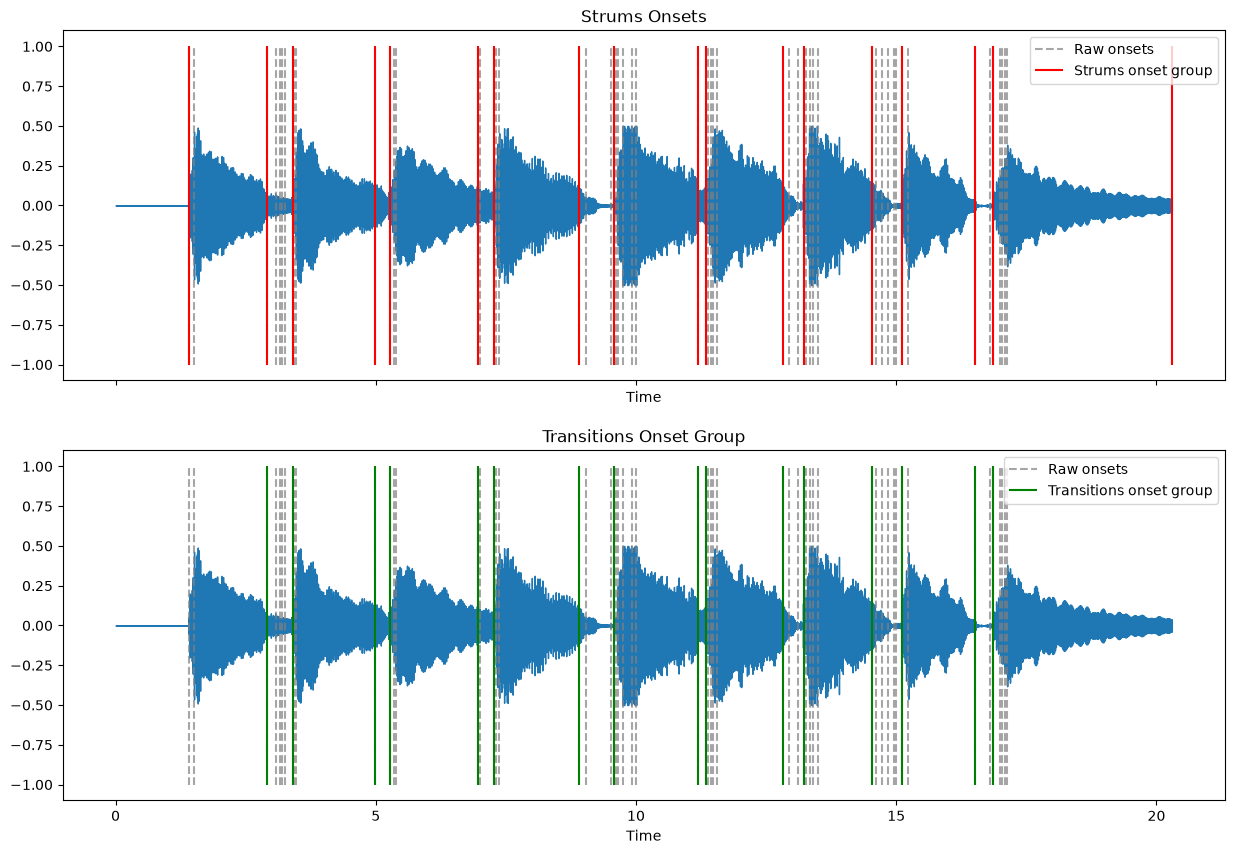

In [15]:
fig, ax = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

librosa.display.waveshow(clip, sr=sr, ax=ax[0])
ax[0].vlines(raw_onset_times, -1, 1, color="grey", linestyle="--", alpha=0.7, label="Raw onsets")
ax[0].vlines(strums_times, -1, 1, color="red", linestyle="-", label="Strums onset group")
ax[0].set_title("Strums Onsets")
ax[0].legend()

librosa.display.waveshow(clip, sr=sr, ax=ax[1])
ax[1].vlines(raw_onset_times, -1, 1, color="grey", linestyle="--", alpha=0.7, label="Raw onsets")
ax[1].vlines(transitions_times, -1, 1, color="green", linestyle="-", label="Transitions onset group")
ax[1].set_title("Transitions Onset Group")
ax[1].set_xlabel("Time")
ax[1].legend()

plt.tight_layout()
plt.show()


Next: I will process the transition times for each chord and return the time in seconds, which can then be expanded into the skill level dictionaries

In [16]:
import time
def get_transition_times(transition_group, sr):
    times = []
    for start, end in transition_group:
        frames = end - start
        transition_time = librosa.frames_to_time(frames, sr=sr)
        times.append(transition_time)
    return times

In [17]:
times = get_transition_times(transitions, sr)
for t in times:
    mins, secs = divmod(t, 60)
    print(f"{secs:05.2f} seconds")

00.49 seconds
00.28 seconds
00.30 seconds
00.67 seconds
00.15 seconds
00.39 seconds
00.58 seconds
00.34 seconds


In [18]:
import sys
sys.path.insert(0, "../fretwave")
from chord_detect import detect_chords
detected = detect_chords(strum_group, chroma)

Chord: C, Score:90.15%
Chord: G, Score:93.20%
Chord: D, Score:90.65%
Chord: Dm, Score:91.47%
Chord: Em, Score:92.88%
Chord: E, Score:92.74%
Chord: Am, Score:92.81%
Chord: F, Score:89.35%
Chord: A, Score:87.59%


In [19]:
from skill_levels import skill_levels, chord_accepted
for chord, score in detected: 
    chord_accepted("advanced", chord, score)

Chord C detected!
Chord G detected!
Chord D detected!
Chord Dm detected!
Chord Em detected!
Chord E detected!
Chord Am detected!
Chord accuracy 89.35 is below the threshold for advanced guitar players (90)
Chord accuracy 87.59 is below the threshold for advanced guitar players (90)


## Sources

- stachyra (2017) 'Recorded audio of one note produces multiple onset times' [online] Stack Overflow, Available at: https://stackoverflow.com/questions/44013269/recorded-audio-of-one-note-produces-multiple-onset-times/44214229#44214229 [Accessed: 14th Nov 2026]
- Python tutorial - basics of automatic music transcription - III onset detection (2018) [Video] Directed by The Sound Travels [YouTube] Available at: https://www.youtube.com/watch?v=TXPQrJq0ak0 [Accessed 14th Nov 2026]
- MusicInformationRetrieval (n,d) 'Onset-based Segmentation with Backtracking' [online] mirdotcom, Available at: https://musicinformationretrieval.com/content/4_rhythm_tempo_beat/onset_segmentation.html [Accessed: 14th Nov 2026]
- Let’s hit them strings! | MIDI guitar: Onset detection with envelope - original method #ANTech (2021) [Video] Directed by Antoni Jankowski, [YouTube] Available at: https://www.youtube.com/watch?v=2YykLX5nCDQ&t=71s [Accessed 15th Nov 2026]

AI was not used for the development of this notebook